In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import warnings

In [48]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier,plot_tree,export_text
from sklearn.model_selection import train_test_split, KFold, LeaveOneOut
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, cohen_kappa_score, ConfusionMatrixDisplay, precision_score, recall_score, f1_score, roc_curve,auc)
from sklearn.preprocessing import minmax_scale

In [ ]:
LeaveOneOut

In [3]:
fruits = pd.read_csv("C:/Dataset/fruits.csv")
X = fruits[['sphericity',	'weight']]
Y = fruits[['label']]
fruits

,color,sphericity,weight,label
0,Orange,0.947,120,Orange
1,Orange,0.917,125,Orange
2,Orange,0.923,110,Orange
3,Orange,0.916,123,Orange
4,Orange,0.943,124,Orange
5,Orange,0.911,130,Orange
6,Orange,0.903,135,Orange
7,Orange,0.918,105,Orange
8,Orange,0.914,132,Orange
9,Orange,0.936,127,Orange


In [4]:
X_train1, X_test1, Y_train1, Y_test1 = train_test_split(X,Y)

In [5]:
X_train1.shape

(45, 2)

In [6]:
X_test1.shape


(15, 2)

In [7]:
X_train2, X_test2, Y_train2, Y_test2 = train_test_split(X,Y)


In [8]:
X_train2.shape

(45, 2)

In [9]:
X_test2.shape

(15, 2)

In [10]:
set(Y_test1.index).intersection(set(Y_test2.index))

{1, 34, 55}

# HOLD OUT METHOD VS K FOLD METHOD 

In [11]:
kf = KFold(n_splits=4)

for ix_train, ix_test in kf.split(X):
    print(ix_train)
    print(ix_test)
    


[15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38
 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 54 55 56 57 58 59]
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 30 31 32 33 34 35 36 37 38
 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 54 55 56 57 58 59]
[15 16 17 18 19 20 21 22 23 24 25 26 27 28 29]
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 45 46 47 48 49 50 51 52 53 54 55 56 57 58 59]
[30 31 32 33 34 35 36 37 38 39 40 41 42 43 44]
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44]
[45 46 47 48 49 50 51 52 53 54 55 56 57 58 59]


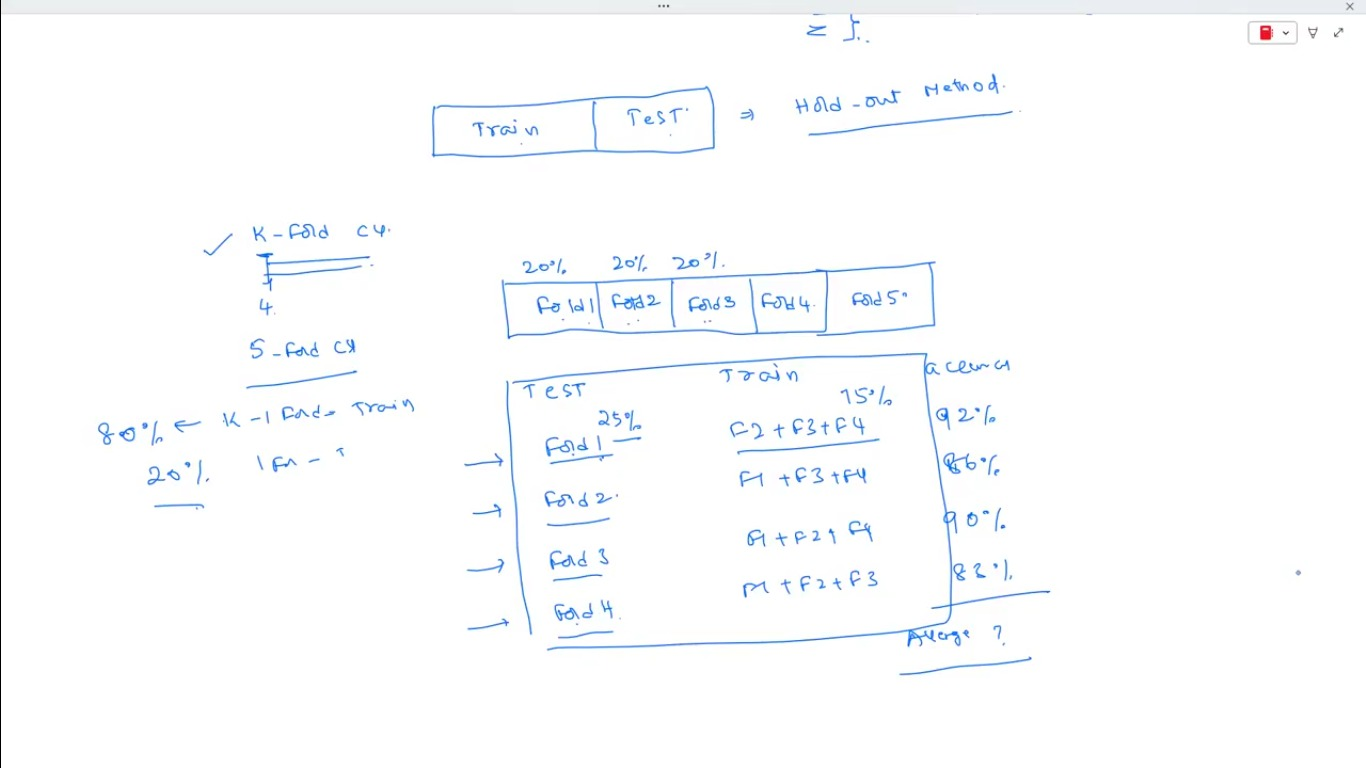

### Class notes: Hold-Out vs K-Fold

- **Hold-Out:** one split, Train | Test, one accuracy score. The score depends on which rows landed in the test set.
- **K-Fold (e.g. 5-fold = 5 x 20%):** 1 fold = test, K-1 folds = train (80% / 20%). Repeat K times and **average** the fold scores.
- **Advantage:** every sample is used for testing exactly once.
- `kf.split(X, y)` returns **indexes** (`ix_train`, `ix_test`); use `.iloc[...]` to get the actual data.

**Industry note:** 5 or 10 folds is standard; keep a separate final test set, and report **mean ± std**, not just the mean.

# CASE 2

In [12]:
# on shuffle =True data will be but in ascending order and data will be unique sample 
kf = KFold(n_splits=4, shuffle=True)

for ix_train, ix_test in kf.split(X):
    print(ix_train)
    print(ix_test)

[ 0  1  2  3  6  8  9 10 11 13 14 15 16 17 19 22 23 24 25 26 27 29 31 33
 35 36 37 38 39 40 41 43 44 46 47 48 49 50 51 52 53 54 55 56 59]
[ 4  5  7 12 18 20 21 28 30 32 34 42 45 57 58]
[ 0  1  2  3  4  5  6  7  9 11 12 14 15 16 17 18 19 20 21 22 25 26 27 28
 29 30 31 32 34 35 36 37 39 42 44 45 47 48 49 50 51 56 57 58 59]
[ 8 10 13 23 24 33 38 40 41 43 46 52 53 54 55]
[ 1  3  4  5  7  8  9 10 12 13 18 19 20 21 23 24 25 27 28 29 30 31 32 33
 34 36 38 40 41 42 43 44 45 46 47 48 49 51 52 53 54 55 56 57 58]
[ 0  2  6 11 14 15 16 17 22 26 35 37 39 50 59]
[ 0  2  4  5  6  7  8 10 11 12 13 14 15 16 17 18 20 21 22 23 24 26 28 30
 32 33 34 35 37 38 39 40 41 42 43 45 46 50 52 53 54 55 57 58 59]
[ 1  3  9 19 25 27 29 31 36 44 47 48 49 51 56]


# case 3

In [18]:
kf = KFold(n_splits=5, shuffle=True)

for ix_train, ix_test in kf.split(fruits):
    print(ix_train)
    print(ix_test)

[ 0  1  5  6  7  8  9 10 11 12 13 14 16 17 18 19 20 21 22 24 25 26 27 28
 30 31 32 33 34 35 36 38 39 43 44 45 46 47 48 49 51 52 53 55 56 57 58 59]
[ 2  3  4 15 23 29 37 40 41 42 50 54]
[ 1  2  3  4  6  7  8 11 13 14 15 16 17 19 20 21 22 23 24 26 27 29 31 32
 33 34 35 36 37 38 39 40 41 42 43 44 46 47 48 49 50 51 52 54 55 56 57 58]
[ 0  5  9 10 12 18 25 28 30 45 53 59]
[ 0  1  2  3  4  5  6  7  9 10 12 13 14 15 16 18 19 23 25 26 27 28 29 30
 31 32 33 34 35 36 37 38 39 40 41 42 44 45 46 48 49 50 51 53 54 55 58 59]
[ 8 11 17 20 21 22 24 43 47 52 56 57]
[ 0  1  2  3  4  5  6  8  9 10 11 12 15 16 17 18 20 21 22 23 24 25 27 28
 29 30 33 35 36 37 40 41 42 43 44 45 46 47 48 49 50 52 53 54 56 57 58 59]
[ 7 13 14 19 26 31 32 34 38 39 51 55]
[ 0  2  3  4  5  7  8  9 10 11 12 13 14 15 17 18 19 20 21 22 23 24 25 26
 28 29 30 31 32 34 37 38 39 40 41 42 43 45 47 50 51 52 53 54 55 56 57 59]
[ 1  6 16 27 33 35 36 44 46 48 49 58]


In [24]:
kf = KFold(n_splits=4, shuffle=True)

for ix_train, ix_test in kf.split(X,Y):
    X_train, X_test, Y_train, Y_test = X.iloc[ix_train], X.iloc[ix_test], Y.iloc[ix_train], Y.iloc[ix_test]
    print(X_train.shape, X_test.shape, Y_train.shape, Y_test.shape)


(45, 2) (15, 2) (45, 1) (15, 1)
(45, 2) (15, 2) (45, 1) (15, 1)
(45, 2) (15, 2) (45, 1) (15, 1)
(45, 2) (15, 2) (45, 1) (15, 1)


In [44]:
kf = KFold(n_splits=4, shuffle=True)
accuracy =[]
cappa=[]
recall=[]
model = DecisionTreeClassifier(criterion='entropy', random_state=10)

for ix_train, ix_test in kf.split(X,Y):
    X_train, X_test, Y_train, Y_test = X.iloc[ix_train], X.iloc[ix_test], Y.iloc[ix_train], Y.iloc[ix_test]
    model.fit(X_train, Y_train)
    y_predict = model.predict(X_test)
    accuracy.append(accuracy_score(Y_test, y_predict))
    cappa.append(cohen_kappa_score(Y_test, y_predict))
    recall.append(recall_score(Y_test, y_predict, pos_label='Apple'))
accuracy
    # print(X_train.shape, X_test.shape, Y_train.shape, Y_test.shape)

[1.0, 1.0, 0.9333333333333333, 1.0]

In [45]:
accuracy, cappa, recall


([1.0, 1.0, 0.9333333333333333, 1.0],
 [1.0, 1.0, 0.8571428571428572, 1.0],
 [1.0, 1.0, 1.0, 1.0])

In [46]:
np.mean(accuracy), np.mean(cappa), np.mean(recall)

(np.float64(0.9833333333333334),
 np.float64(0.9642857142857143),
 np.float64(1.0))

in KFold CrossValidation this K is replaced  by how many no. of samples is called n-fold it is also called n-fold cross validation 
Ex:- The leave-one-out method (most commonly leave-one-out cross-validation, or LOOCV) is a model evaluation technique where a model is trained on all data points except one, tested on the single excluded point, and repeated for every point in a dataset of size n. It is a special case of k-fold cross-validation where k equals n.
• Split: Hold out one sample as the test set and use the remaining n − 1 samples for training.
• Repeat: Train and test n times so every single data point serves as the test set once.
• Aggregate: Average the error or performance score across all n iterations
Note: ``LeaveOneOut()`` is equivalent to ``KFold(n_splits=n)`` and
``LeavePOut(p=1)`` where ``n`` is the number of samples.

# Industry style: `cross_validate` with a Pipeline

The manual loop above is for learning. In projects, use a `Pipeline` (prevents data leakage) and `cross_validate` (several metrics in one call). Report **mean ± std**.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

y_flat = Y['label']
model = make_pipeline(StandardScaler(), DecisionTreeClassifier(criterion='entropy', random_state=10))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

res = cross_validate(model, X, y_flat, cv=cv,
                     scoring=['accuracy', 'balanced_accuracy', 'f1_macro'],
                     return_train_score=True)
for k, v in res.items():
    if k.startswith(('test_', 'train_')):
        print(f"{k:28s} {v.mean():.3f} ± {v.std():.3f}")

**Reading the result:** a big gap between `train_*` and `test_*` scores means over-fitting (decision trees often reach 100% on train).